# Loan Approval Prediction System Using Machine Learning

**Internship Program:** Infobharat Interns  
**Domain:** Machine Learning  
**Project Type:** Supervised Classification  
**Programming Language:** Python

## 1. Project Overview

The Loan Approval Prediction System is a machine learning project designed to predict whether a loan application is likely to be approved or rejected using applicant demographics, employment details, and financial information.

The project demonstrates an end-to-end machine learning workflow, including dataset generation, data preprocessing, exploratory data analysis, data visualization, model training, performance evaluation, and interactive prediction.

### Project Objectives

- Generate a synthetic dataset containing at least 1,500 loan applicant records.
- Clean and preprocess the dataset.
- Explore relationships between financial features and loan approval.
- Create meaningful visualizations to communicate data insights.
- Train and compare classification algorithms.
- Evaluate model performance using standard classification metrics.
- Develop an interactive loan prediction interface.

### Technologies Used

Python, NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn, and Joblib.

### Expected Deliverables

A Jupyter Notebook, Python source file, CSV dataset, README documentation, visualizations, and GitHub repository.

**Note:** This project uses synthetic data and is intended for educational purposes. Its predictions are not actual lending decisions.

## 2. Import Libraries and Initialize the Environment

This section imports the libraries required for data manipulation, numerical computation, visualization, data preprocessing, classification, model evaluation, and model serialization.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully.
Pandas version: 2.2.3
NumPy version: 2.1.3


## 3. Synthetic Dataset Generation

A synthetic dataset will be created using NumPy and Pandas to represent 2,000 loan applicants.

The dataset contains demographic information, financial attributes, employment status, property area, and the target variable `LoanApproved`.

The approval labels are generated using an illustrative probability formula that incorporates credit score, income relative to the requested loan amount, employment status, existing loans, and property area.

In [3]:
np.random.seed(42)

n = 2000

data = pd.DataFrame({
    "ApplicantID": range(1001, 1001 + n),
    "Gender": np.random.choice(["Male", "Female"], n),
    "Age": np.random.randint(21, 61, n),
    "MonthlyIncome": np.random.randint(15000, 150001, n),
    "CreditScore": np.clip(
        np.random.normal(680, 65, n).astype(int),
        300, 850
    ),
    "EmploymentStatus": np.random.choice(
        ["Employed", "Self-Employed", "Unemployed"],
        n,
        p=[0.60, 0.30, 0.10]
    ),
    "ExistingLoans": np.random.choice(
        [0, 1, 2, 3, 4, 5],
        n,
        p=[0.25, 0.25, 0.20, 0.15, 0.10, 0.05]
    ),
    "LoanTerm": np.random.choice(
        [12, 24, 36, 48, 60], n
    ),
    "PropertyArea": np.random.choice(
        ["Urban", "Semi-Urban", "Rural"], n
    )
})

data["LoanAmount"] = np.random.randint(20000, 1000001, n)

income_ratio = (
    data["LoanAmount"] / (data["MonthlyIncome"] * 12)
).clip(0, 5)

score = (
    0.035 * (data["CreditScore"] - 650)
    + 0.8 * (data["EmploymentStatus"] == "Employed")
    + 0.5 * (data["EmploymentStatus"] == "Self-Employed")
    - 0.7 * (data["EmploymentStatus"] == "Unemployed")
    - 0.35 * data["ExistingLoans"]
    - income_ratio
    + 0.3 * (data["PropertyArea"] == "Urban")
    + 0.15 * (data["PropertyArea"] == "Semi-Urban")
)

probability = 1 / (1 + np.exp(-score))

data["LoanApproved"] = (
    np.random.random(n) < probability
).astype(int)

# Introduce missing values for preprocessing practice
for column in [
    "Gender", "Age", "MonthlyIncome",
    "LoanAmount", "CreditScore", "EmploymentStatus"
]:
    missing_indices = data.sample(
        frac=0.01, random_state=42
    ).index
    data.loc[missing_indices, column] = np.nan

data.to_csv("loan_approval_dataset.csv", index=False)

print("Dataset generated successfully.")
print("Number of records:", len(data))
print("Number of columns:", len(data.columns))

display(data.head())

Dataset generated successfully.
Number of records: 2000
Number of columns: 11


,ApplicantID,Gender,Age,MonthlyIncome,CreditScore,EmploymentStatus,ExistingLoans,LoanTerm,PropertyArea,LoanAmount,LoanApproved
0,1001,Male,32.0,136534.0,722.0,Self-Employed,0,36,Semi-Urban,735030.0,0
1,1002,Female,36.0,99227.0,656.0,Employed,1,48,Semi-Urban,748493.0,1
2,1003,Male,44.0,86126.0,662.0,Self-Employed,1,36,Rural,115856.0,1
3,1004,Male,39.0,71071.0,709.0,Employed,1,60,Semi-Urban,444477.0,1
4,1005,Male,28.0,89763.0,649.0,Employed,3,12,Rural,732514.0,1


## 4. Dataset Inspection and Data Quality Assessment

This section examines the dataset structure, data types, missing values, duplicate records, and target distribution.

The inspection helps identify data quality issues before model development and confirms that the generated dataset contains the expected features.

In [4]:
print("Dataset shape:", data.shape)

print("\nDataset information:")
data.info()

print("\nMissing values:")
display(data.isnull().sum().to_frame("Missing Count"))

print("\nDuplicate rows:", data.duplicated().sum())

print("\nTarget distribution:")
display(data["LoanApproved"].value_counts())

print("\nTarget distribution in percentages:")
display(
    data["LoanApproved"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Dataset shape: (2000, 11)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ApplicantID       2000 non-null   int64  
 1   Gender            1980 non-null   object 
 2   Age               1980 non-null   float64
 3   MonthlyIncome     1980 non-null   float64
 4   CreditScore       1980 non-null   float64
 5   EmploymentStatus  1980 non-null   object 
 6   ExistingLoans     2000 non-null   int64  
 7   LoanTerm          2000 non-null   int64  
 8   PropertyArea      2000 non-null   object 
 9   LoanAmount        1980 non-null   float64
 10  LoanApproved      2000 non-null   int64  
dtypes: float64(4), int64(4), object(3)
memory usage: 172.0+ KB

Missing values:


,Missing Count
ApplicantID,0
Gender,20
Age,20
MonthlyIncome,20
CreditScore,20
EmploymentStatus,20
ExistingLoans,0
LoanTerm,0
PropertyArea,0
LoanAmount,20



Duplicate rows: 0

Target distribution:


,count
LoanApproved,
1,1081
0,919



Target distribution in percentages:


,proportion
LoanApproved,
1,54.05
0,45.95


## 5. Data Cleaning and Preprocessing

The dataset is cleaned by removing duplicate records and validating the target variable. The target is separated from the input features, and the applicant identifier is excluded from model training.

Numerical missing values will be imputed using the median, while categorical missing values will be imputed using the most frequent category. Categorical features will be one-hot encoded, and numerical features will be standardized.

The preprocessing pipeline will be fitted only on the training dataset to avoid data leakage.

In [5]:
# Remove duplicates and invalid target values
data = data.drop_duplicates().copy()
data = data.dropna(subset=["LoanApproved"]).copy()
data = data[data["LoanApproved"].isin([0, 1])].copy()

data["LoanApproved"] = data["LoanApproved"].astype(int)

# Separate features and target
X = data.drop(columns=["ApplicantID", "LoanApproved"])
y = data["LoanApproved"]

numeric_features = [
    "Age", "MonthlyIncome", "LoanAmount",
    "CreditScore", "ExistingLoans", "LoanTerm"
]

categorical_features = [
    "Gender", "EmploymentStatus", "PropertyArea"
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Preprocessing pipeline configured successfully.")

Training records: 1600
Testing records: 400
Preprocessing pipeline configured successfully.


## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand applicant characteristics and investigate patterns associated with loan approval.

The following visualizations examine approval distribution, employment status, numerical feature correlations, and the relationship between monthly income and requested loan amount.

### 6.1 Loan Approval Distribution

This visualization compares the number of approved and rejected applications to assess the distribution of the target variable.

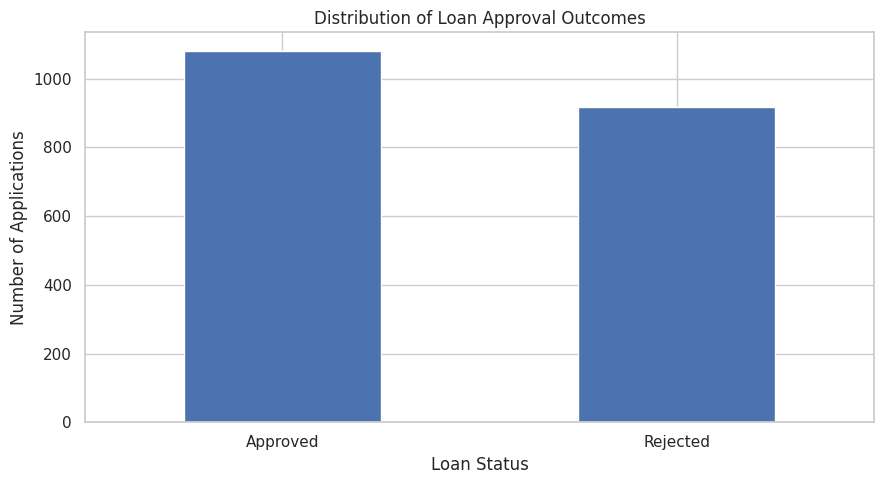

In [6]:
approval_counts = data["LoanApproved"].map({
    0: "Rejected",
    1: "Approved"
}).value_counts()

approval_counts = approval_counts.reindex(
    ["Approved", "Rejected"], fill_value=0
)

approval_counts.plot(kind="bar", rot=0)

plt.title("Distribution of Loan Approval Outcomes")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

### 6.2 Loan Approval by Employment Status

This grouped bar chart compares approved and rejected applications across employment categories. The comparison helps identify differences in the synthetic dataset's approval outcomes by employment status.

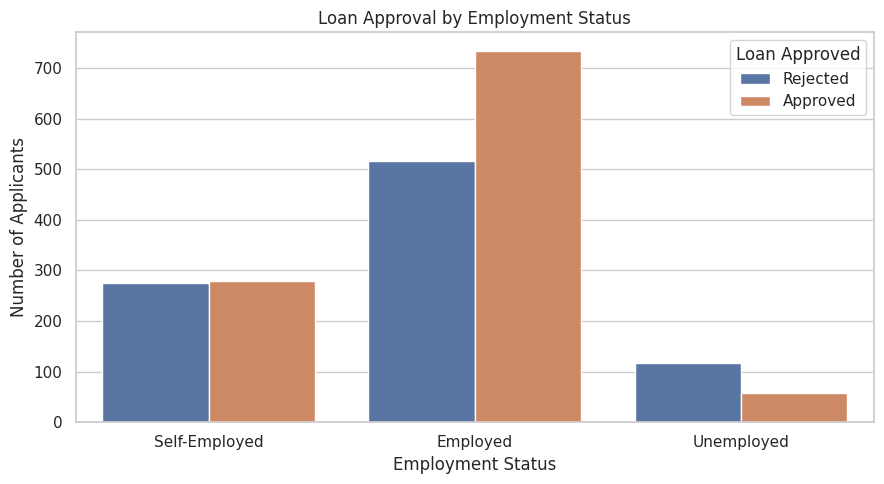

In [7]:
sns.countplot(
    data=data,
    x="EmploymentStatus",
    hue="LoanApproved"
)

plt.title("Loan Approval by Employment Status")
plt.xlabel("Employment Status")
plt.ylabel("Number of Applicants")
plt.legend(title="Loan Approved", labels=["Rejected", "Approved"])
plt.tight_layout()
plt.show()

### 6.3 Correlation Heatmap of Numerical Features

The correlation heatmap visualizes linear relationships among numerical features. Correlation values range from -1 to +1, indicating negative, weak, or positive linear associations.

Correlation does not establish causation, and the target's correlations should be interpreted in the context of the synthetic data-generation process.

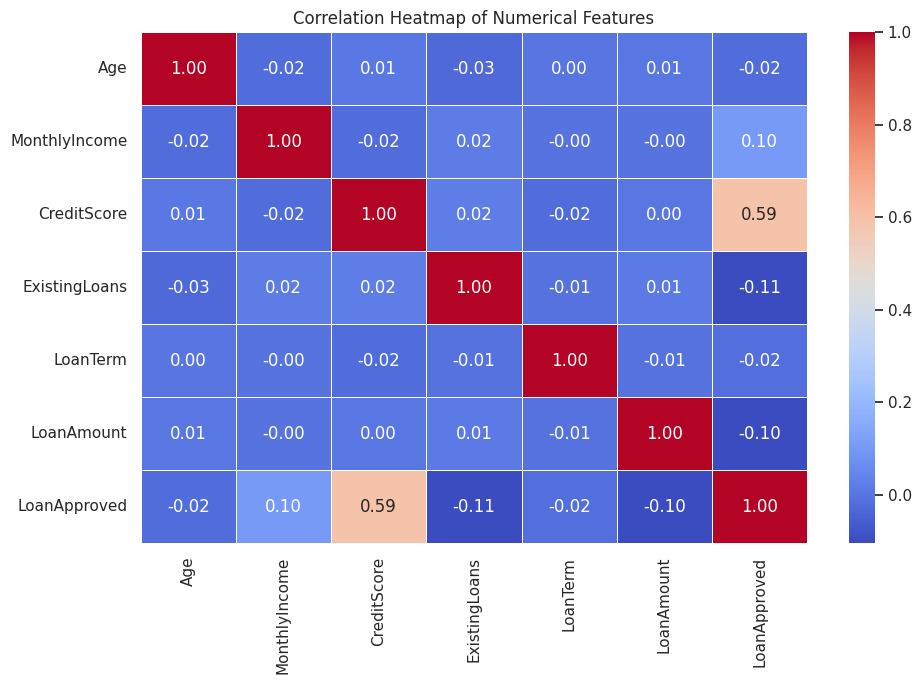

In [8]:
correlation_data = data.select_dtypes(include="number").drop(
    columns=["ApplicantID"], errors="ignore"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

### 6.4 Monthly Income vs. Loan Amount

The scatter plot examines the relationship between applicants' monthly income and requested loan amounts. Points are distinguished by the target label to help visualize patterns in the synthetic dataset.

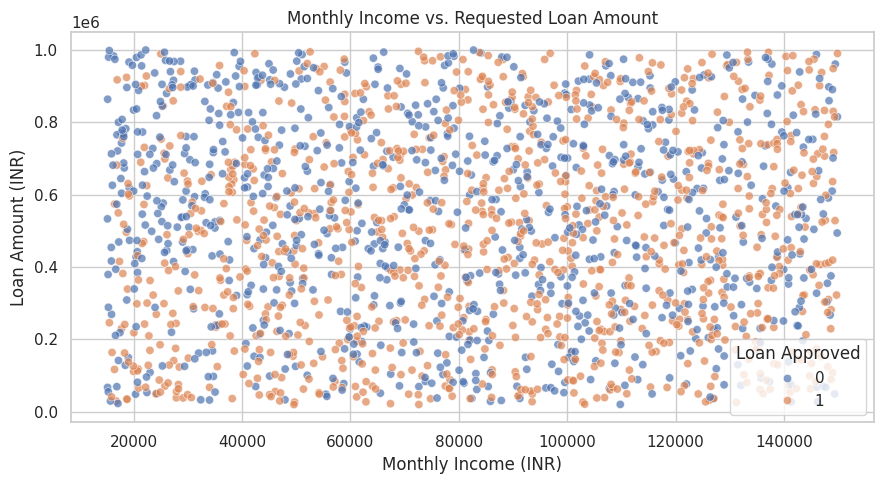

In [9]:
sns.scatterplot(
    data=data,
    x="MonthlyIncome",
    y="LoanAmount",
    hue="LoanApproved",
    alpha=0.7
)

plt.title("Monthly Income vs. Requested Loan Amount")
plt.xlabel("Monthly Income (INR)")
plt.ylabel("Loan Amount (INR)")
plt.legend(title="Loan Approved")
plt.tight_layout()
plt.show()

### 6.5 Key Findings from Exploratory Data Analysis

Review the generated charts and document the observations supported by the data.

Discuss:

- The proportion of approved and rejected applications.
- Differences in approval counts across employment categories.
- Relationships among numerical features.
- Patterns between monthly income, requested loan amount, and approval labels.

**Important:** Complete this section after running the visualizations. Report actual observations rather than assuming that a particular feature always increases the likelihood of approval.

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        random_state=42,
        class_weight="balanced"
    )
}

trained_models = {}
results = []

for name, classifier in models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.772,0.791,0.787,0.789
1,Decision Tree,0.722,0.744,0.741,0.742
2,Random Forest,0.780,0.805,0.782,0.793


## 8. Model Performance Evaluation

Model evaluation measures how effectively each classifier predicts the target labels on unseen test records.

The evaluation includes accuracy, precision, recall, F1-score, classification reports, and confusion matrices.

The model selection decision should consider the trade-offs among these metrics rather than relying on accuracy alone.

Selected model: Random Forest

Classification report:
              precision    recall  f1-score   support

    Rejected       0.75      0.78      0.76       184
    Approved       0.80      0.78      0.79       216

    accuracy                           0.78       400
   macro avg       0.78      0.78      0.78       400
weighted avg       0.78      0.78      0.78       400



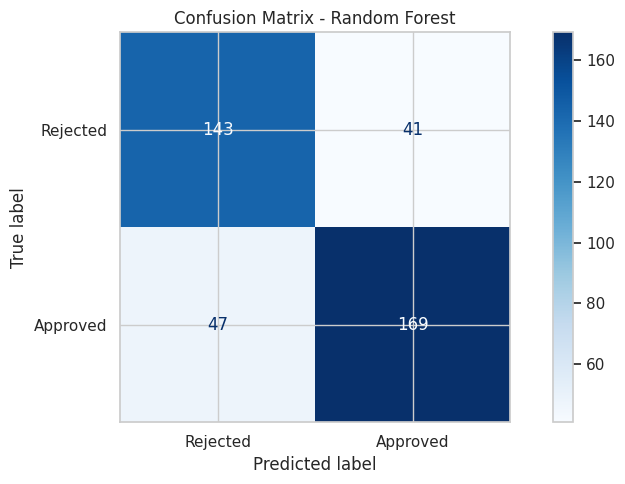

In [11]:
# Select the model with the highest test F1-score
best_model_name = results_df.sort_values(
    "F1 Score", ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]
y_pred = best_model.predict(X_test)

print("Selected model:", best_model_name)
print("\nClassification report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Rejected", "Approved"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Rejected", "Approved"],
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

## 9. Interactive Loan Approval Prediction System

The following console-based interface accepts applicant details and generates a prediction using the selected model.

The interface validates numerical ranges and categorical values before making a prediction. Invalid inputs are handled gracefully to prevent avoidable program crashes.

The system is designed for educational demonstrations and should not be used to make real lending decisions.

In [12]:
def predict_loan():
    try:
        age = int(input("Age (21-100): "))
        income = float(input("Monthly income (INR): "))
        amount = float(input("Loan amount (INR): "))
        credit = int(input("Credit score (300-850): "))
        employment = input(
            "Employment (Employed/Self-Employed/Unemployed): "
        ).strip().lower()
        existing = int(input("Number of existing loans: "))
        term = int(input("Loan term (12/24/36/48/60 months): "))
        area = input(
            "Property area (Urban/Semi-Urban/Rural): "
        ).strip().lower()
        gender = input("Gender (Male/Female): ").strip().lower()

        if not 21 <= age <= 100:
            raise ValueError("Age must be between 21 and 100.")

        if not np.isfinite(income) or income <= 0:
            raise ValueError("Monthly income must be positive.")

        if not np.isfinite(amount) or amount <= 0:
            raise ValueError("Loan amount must be positive.")

        if not 300 <= credit <= 850:
            raise ValueError("Credit score must be between 300 and 850.")

        if existing < 0:
            raise ValueError("Existing loans cannot be negative.")

        if term not in [12, 24, 36, 48, 60]:
            raise ValueError("Invalid loan term.")

        employment_map = {
            "employed": "Employed",
            "self-employed": "Self-Employed",
            "unemployed": "Unemployed"
        }

        area_map = {
            "urban": "Urban",
            "semi-urban": "Semi-Urban",
            "rural": "Rural"
        }

        gender_map = {
            "male": "Male",
            "female": "Female"
        }

        if employment not in employment_map:
            raise ValueError("Invalid employment status.")

        if area not in area_map:
            raise ValueError("Invalid property area.")

        if gender not in gender_map:
            raise ValueError("Invalid gender.")

        applicant = pd.DataFrame([{
            "Gender": gender_map[gender],
            "Age": age,
            "MonthlyIncome": income,
            "LoanAmount": amount,
            "CreditScore": credit,
            "EmploymentStatus": employment_map[employment],
            "ExistingLoans": existing,
            "LoanTerm": term,
            "PropertyArea": area_map[area]
        }])

        prediction = best_model.predict(applicant)[0]

        label = "Approved" if prediction == 1 else "Rejected"

        print("\nLoan Approval Prediction:", label)
        print("Educational prediction only; not a lending decision.")

    except (ValueError, TypeError) as error:
        print("Input error:", error)


predict_loan()

Age (21-100): 22
Monthly income (INR): 500000
Loan amount (INR): 7000000
Credit score (300-850): 750
Employment (Employed/Self-Employed/Unemployed): employed
Number of existing loans: 1
Loan term (12/24/36/48/60 months): 12
Property area (Urban/Semi-Urban/Rural): urban
Gender (Male/Female): male

Loan Approval Prediction: Approved
Educational prediction only; not a lending decision.


## 10. Save the Trained Model and Dataset

The selected model pipeline will be serialized using Joblib so that it can be reused without retraining. The cleaned dataset will also be exported as a CSV file.

The pipeline contains both preprocessing transformations and the trained classifier.

In [13]:
joblib.dump(best_model, "loan_approval_model.pkl")

data.to_csv("loan_approval_dataset.csv", index=False)

print("Model saved: loan_approval_model.pkl")
print("Dataset saved: loan_approval_dataset.csv")

Model saved: loan_approval_model.pkl
Dataset saved: loan_approval_dataset.csv


## 11. Conclusion and Future Enhancements

The Loan Approval Prediction System demonstrates the fundamental stages of a supervised machine learning project, from synthetic data generation and preprocessing to exploratory analysis, classification, and interactive prediction.

The comparative evaluation of Logistic Regression, Decision Tree, and Random Forest provides a practical understanding of model performance and classification metrics.

### Limitations

- The dataset is synthetic and may not represent real lending data.
- Target labels are generated using an illustrative formula.
- Performance on synthetic records does not establish real-world predictive ability.
- Real lending applications require appropriate fairness, privacy, explainability, validation, and regulatory safeguards.

### Future Enhancements

- Develop a Streamlit-based web application.
- Add feature importance and explainability analysis.
- Generate downloadable prediction reports.
- Perform more comprehensive model validation.
- Deploy an educational demonstration online.

### Final Deliverables

- Jupyter Notebook (`.ipynb`)
- Python source file (`.py`)
- Synthetic dataset (`.csv`)
- Project documentation (`README.md`)
- Visualization screenshots
- GitHub repository link